In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp
import anndata as ad
import gseapy as gp
from copy import deepcopy
import scanpy.external as sce

# sc.logging.print_version()
sc.settings.verbosity = 3
sc.set_figure_params(figsize=(5,5))

import sys
from pathlib import Path

_start = Path.cwd().resolve()
_repo_root = next((p for p in [_start, *_start.parents] if (p / "chronopack").exists()), _start)
if str(_repo_root) not in sys.path:
    sys.path.insert(0, str(_repo_root))

import chronopack as cp
from chronopack.tl._trajectories import (
    PlotHardClusterMassProportionsOverTime,
    fate_umap_2x2_scanpy,
    mass_retention_plots_and_umap,
)


# Load preprocessing checkpoint

In [2]:
adata_full = sc.read_h5ad("../output/adata_full.chk0.h5ad")
adata_hvg = sc.read_h5ad("../output/adata_hvg.chk0.h5ad")
adata_hvg.obs["time"] = pd.to_numeric(adata_hvg.obs["time"].astype(str))
adata_hvg.X = adata_hvg.layers["corrected"].copy()


## Waddington-OT (Transport Maps)

Compute WOT transition maps from the preprocessed, corrected AnnData checkpoint.

In [3]:
wot_out = cp.tl.get_trajectories(
    adata_hvg,
    tmap_dir="tmaps_sc/",
    ot_model_kwargs=dict(epsilon=0.05, lambda1=1, lambda2=50, growth_iters=3, day_field="time"),
    compute_transport_maps=True,
    transition_topk=30,
    symmetrize="average",
    use_unpruned_as_pruned=True,
    graph_key="ot_graph",
    umap_key="X_ot_umap",
    umap_random_state=10,
)

tmaps = wot_out["tmaps"]
transitions_long = wot_out["transitions_long"]
tmats = wot_out["tmats"]
T_full = wot_out["T_full"]
T_pruned = wot_out["T_pruned"]
T_sym = wot_out["T_sym"]
adata_hvg.obsp["t_pruned"] = T_pruned
key_out = "X_ot_umap"
adata_hvg.obsm["X_umap"][:, 0] *= -1
adata_hvg.obsm[key_out] = adata_hvg.obsm["X_umap"].copy()


Built 11 transport matrices.


/new-stg/home/alex/miniconda3/envs/chronopack-manuscript-20260919/lib/python3.13/site-packages/scanpy/tools/_utils.py:40: UserWarning: You’re trying to run this on 3000 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  warnings.warn(


# Cluster trajectories

Terminal timepoint: 12 | n_terminal=370
Computed terminal distributions for time bin 11/12 (n=310)
Computed terminal distributions for time bin 10/12 (n=306)
Computed terminal distributions for time bin 9/12 (n=426)
Computed terminal distributions for time bin 8/12 (n=310)
Computed terminal distributions for time bin 7/12 (n=386)
Computed terminal distributions for time bin 6/12 (n=340)
Computed terminal distributions for time bin 5/12 (n=269)
Computed terminal distributions for time bin 4/12 (n=299)
Computed terminal distributions for time bin 3/12 (n=307)
Computed terminal distributions for time bin 2/12 (n=348)
Computed terminal distributions for time bin 1/12 (n=363)
Stored adata.obsm['terminal_cell_dist'] with shape (4034, 370) (sparse nnz=733170)


/new-stg/home/alex/tmp/ChronoPack/src/chronopack/tl/_trajectories.py:430: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  _scanpy().tl.leiden(


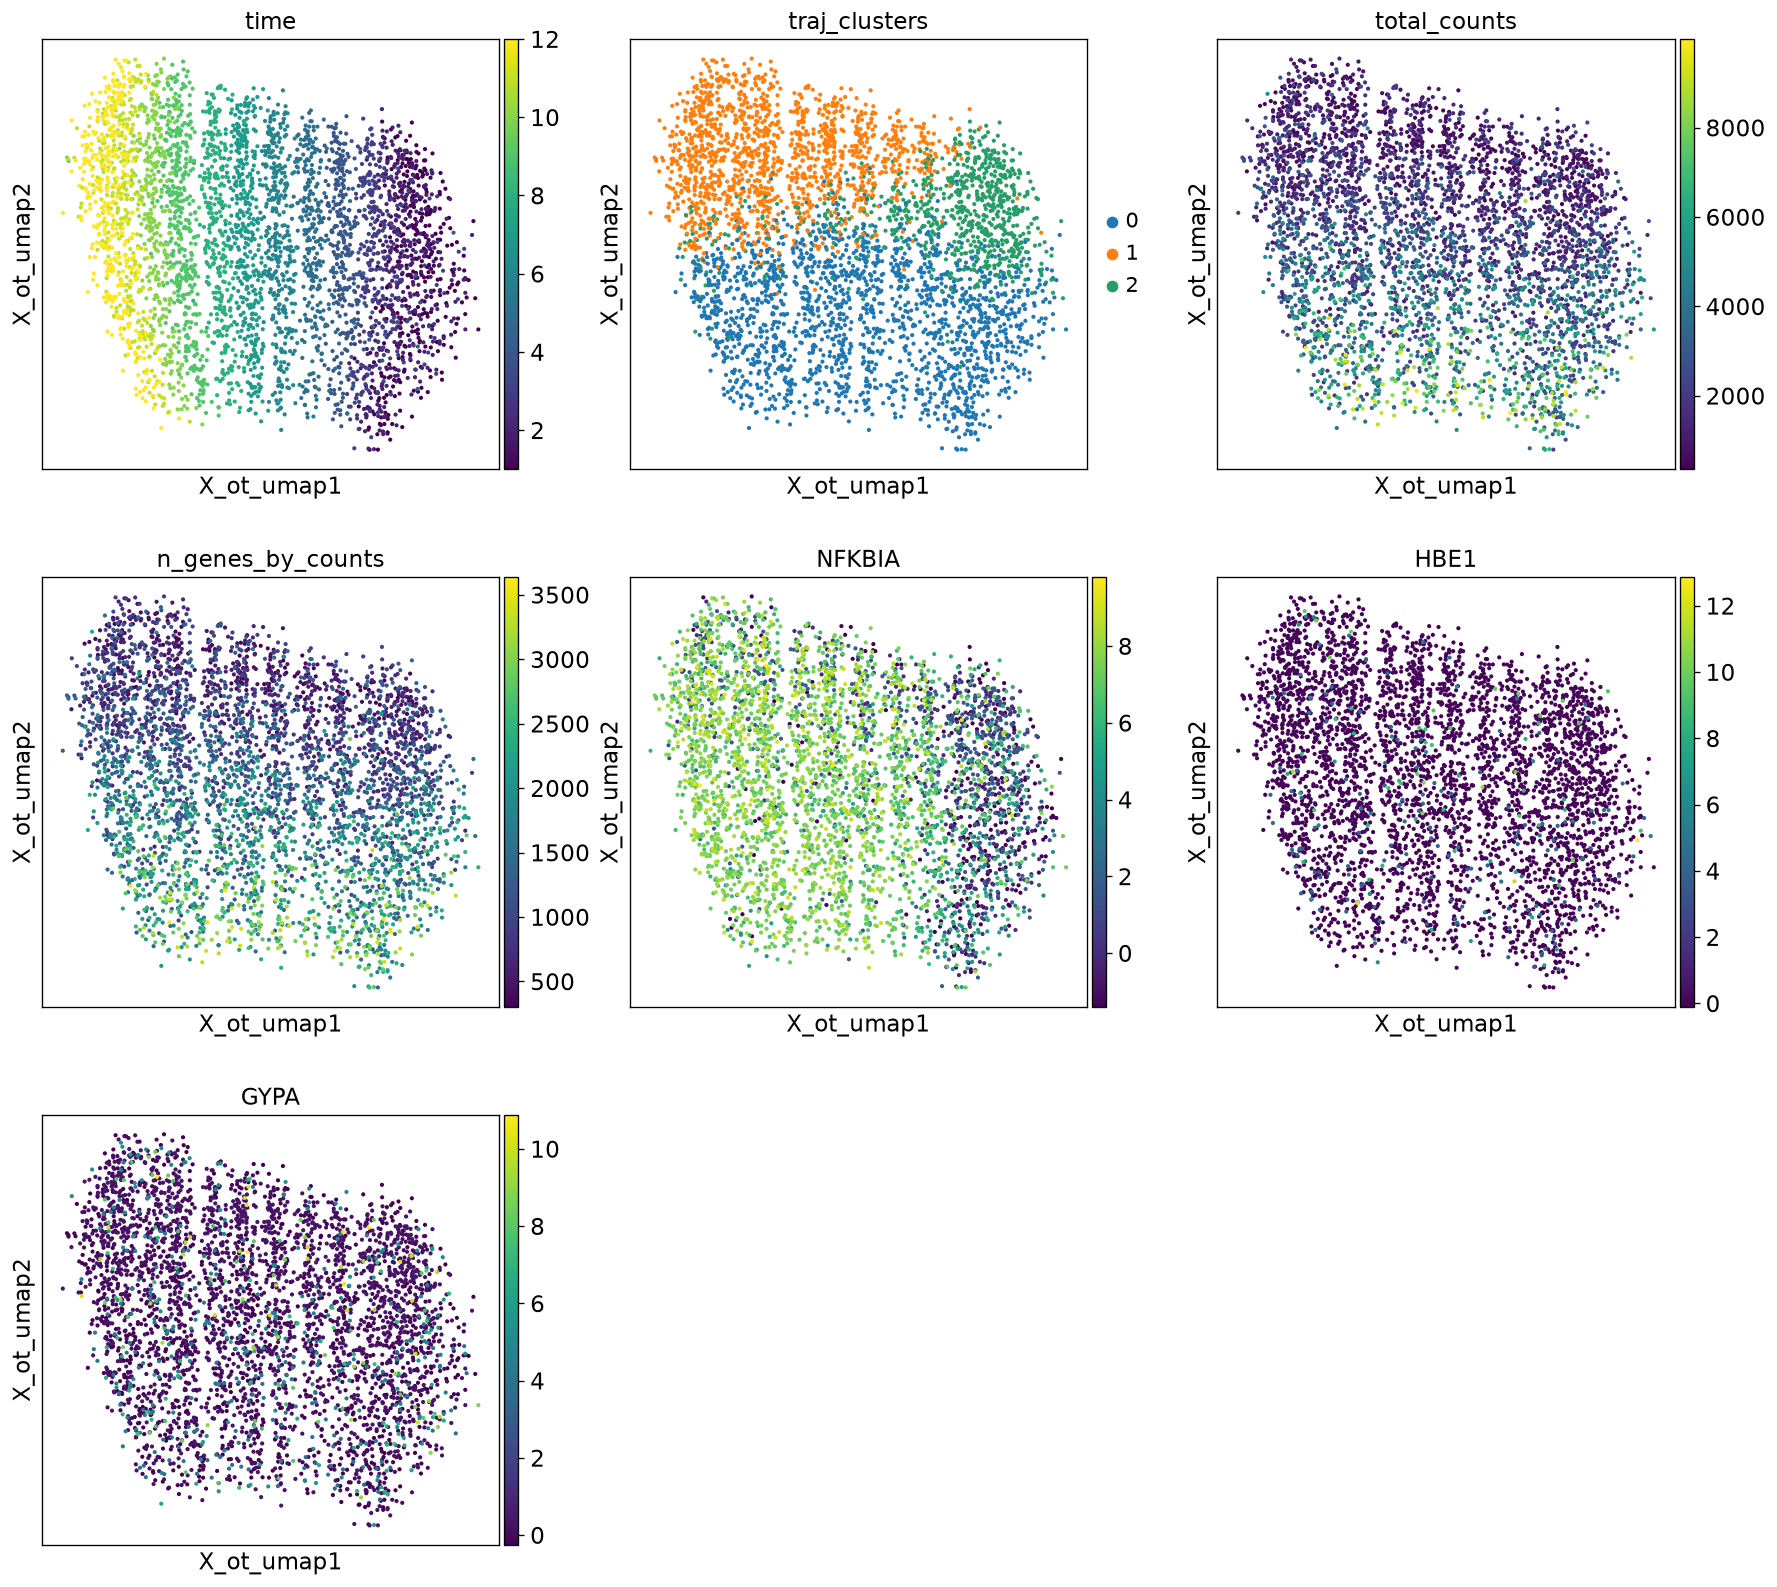

In [4]:
W_pruned = cp.tl.cluster_cell_state_trajectories(
    adata_hvg,
    T_pruned,
    cluster_key="traj_clusters",
    resolution=0.5,
    terminal_topk=200,
    graph_topk=500,
    random_state=0,
)
sc.pl.embedding(
    adata_hvg,
    basis=key_out,
    color=["time", "traj_clusters", "total_counts", "n_genes_by_counts", "NFKBIA", "HBE1", "GYPA"],
    ncols=3,
    cmap="viridis",
    size=25,
)


# Calculate terminal fates & trajectory cluster mass retention

(<Figure size 400x360 with 8 Axes>, array([[<Axes: title={'center': 'Fate prob: 0'}, xlabel='X_ot_umap1', ylabel='X_ot_umap2'>,
        <Axes: title={'center': 'Fate prob: 1'}, xlabel='X_ot_umap1', ylabel='X_ot_umap2'>],
       [<Axes: title={'center': 'Fate entropy (norm)'}, xlabel='X_ot_umap1', ylabel='X_ot_umap2'>,
        <Axes: title={'center': 'Fate maxprob'}, xlabel='X_ot_umap1', ylabel='X_ot_umap2'>]],
      dtype=object))

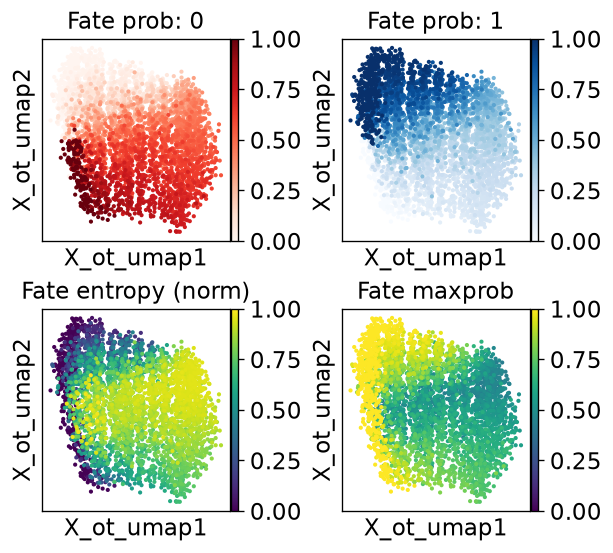

In [5]:
F, fate_names = cp.tl.compute_terminal_fate_probabilities(
    adata_hvg,
    terminal_cluster_key="traj_clusters",
    out_key="terminal_fate_probs_traj",
)
fate_umap_2x2_scanpy(
    adata_hvg,
    fate_key="terminal_fate_probs_traj",
    fate_names_key="terminal_fate_probs_traj_fates",
    umap_basis=key_out,
    size=25,
)


/new-stg/home/alex/miniconda3/envs/chronopack-manuscript-20260919/lib/python3.13/site-packages/scipy/sparse/_index.py:210: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_arrayXarray(i, j, x)


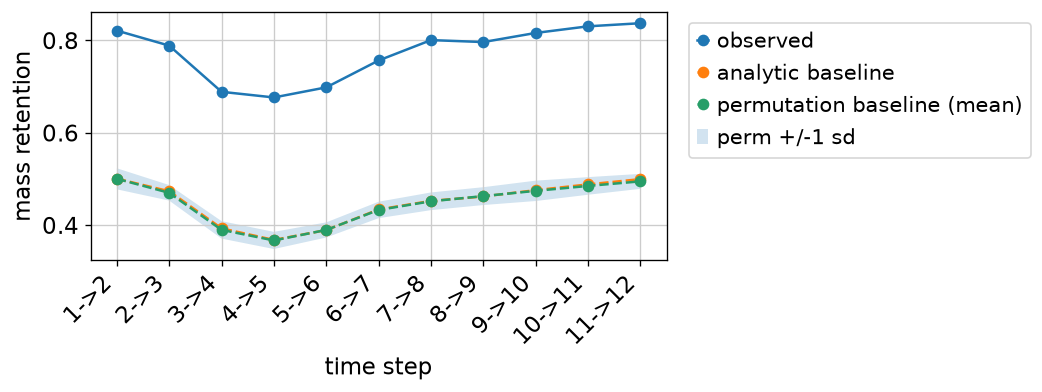

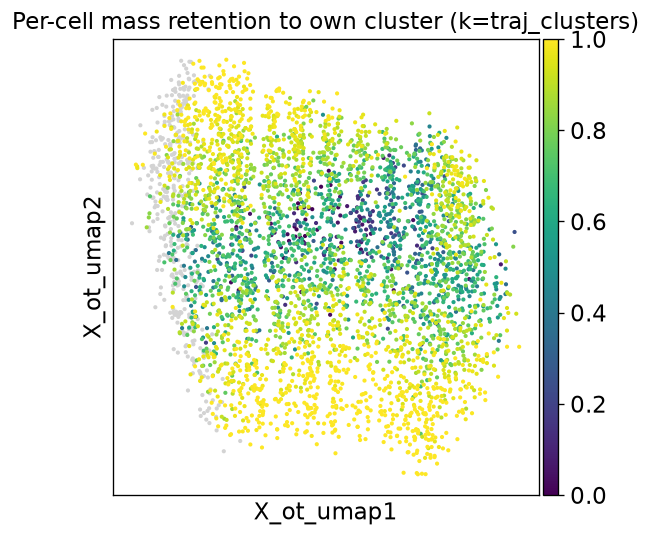

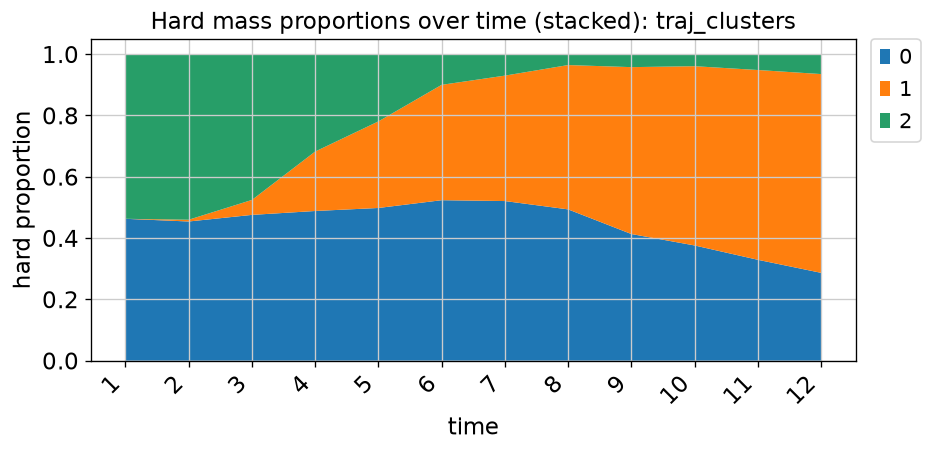

In [6]:
out = mass_retention_plots_and_umap(
    adata_hvg,
    T_pruned,
    cluster_key="traj_clusters",
    n_reps=50,
    clusters_to_plot=["0", "1"],
    umap_basis=key_out,
    size=25,
)
PlotHardClusterMassProportionsOverTime(adata_hvg, cluster_key="traj_clusters")


# Save trajectory outputs

In [7]:
adata_full_out = adata_full[adata_hvg.obs_names, :].copy()
adata_full_out.obs = adata_hvg.obs.copy()
adata_full_out.obsm = adata_hvg.obsm.copy()
adata_full_out.obsp = adata_hvg.obsp.copy()
adata_full_out.uns = adata_hvg.uns.copy()

for _adata_to_write in (adata_full_out, adata_hvg):
    for _key, _value in list(_adata_to_write.uns.items()):
        if isinstance(_value, pd.Series):
            _adata_to_write.uns[_key] = _value.to_frame("value")

adata_full_out.write_h5ad("../output/adata_full.h5ad")
adata_hvg.write_h5ad("../output/adata_hvg.h5ad")
